Build a sentiment analysis model using a pre-trained transformer by fine-tuning models like BERT, RoBERTa, or DistilBERT on domain-specific data, incorporating transfer learning, and optimizing inference efficiency for real-time applications.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
import pandas as pd
import os

# Load the saved final dataset
df = pd.read_pickle("saved_data/womens_clothing_final.pkl")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'saved_data/womens_clothing_final.pkl'

Create the sentiment dataset

In [ ]:
# Create a separate dataset for transformer sentiment analysis
sentiment_df = df[["review_text", "rating"]].copy()

# Remove missing and empty reviews
sentiment_df.dropna(subset=["review_text", "rating"], inplace=True)

sentiment_df["review_text"] = (
    sentiment_df["review_text"].astype(str).str.strip()
)

sentiment_df = sentiment_df[
    sentiment_df["review_text"] != ""
].copy()

# Create sentiment labels from ratings
def assign_sentiment(rating):
    if rating <= 2:
        return 0       # Negative
    elif rating == 3:
        return 1       # Neutral
    else:
        return 2       # Positive

sentiment_df["sentiment"] = sentiment_df["rating"].apply(
    assign_sentiment
)

# Display results
print("Dataset Shape:", sentiment_df.shape)

print("\nSentiment Distribution:")
print(sentiment_df["sentiment"].value_counts().sort_index())

print("\nSample Reviews:")
display(sentiment_df.head(10))

Dataset Shape: (23483, 3)

Sentiment Distribution:
sentiment
0     2407
1     2871
2    18205
Name: count, dtype: int64

Sample Reviews:


,review_text,rating,sentiment
0,Absolutely wonderful - silky and sexy and comfortable,4,2
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",5,2
2,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",3,1
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!",5,2
4,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this shirt!!!,5,2
5,"I love tracy reese dresses, but this one is not for the very petite. i am just under 5 feet tall and usually wear a 0p in this brand. this dress was very pretty out of the package but its a lot of dress. the skirt is long and very full so it overwhelmed my small frame. not a stranger to alterations, shortening and narrowing the skirt would take away from the embellishment of the garment. i love the color and the idea of the style but it just did not work on me. i returned this dress.",2,0
6,"I aded this in my basket at hte last mintue to see what it would look like in person. (store pick up). i went with teh darkler color only because i am so pale :-) hte color is really gorgeous, and turns out it mathced everythiing i was trying on with it prefectly. it is a little baggy on me and hte xs is hte msallet size (bummer, no petite). i decided to jkeep it though, because as i said, it matvehd everything. my ejans, pants, and the 3 skirts i waas trying on (of which i ]kept all ) oops.",5,2
7,"I ordered this in carbon for store pick up, and had a ton of stuff (as always) to try on and used this top to pair (skirts and pants). everything went with it. the color is really nice charcoal with shimmer, and went well with pencil skirts, flare pants, etc. my only compaint is it is a bit big, sleeves are long and it doesn't go in petite. also a bit loose for me, but no xxs... so i kept it and wil ldecide later since the light color is already sold out in hte smallest size...",4,2
8,I love this dress. i usually get an xs but it runs a little snug in bust so i ordered up a size. very flattering and feminine with the usual retailer flair for style.,5,2
9,"I'm 5""5' and 125 lbs. i ordered the s petite to make sure the length wasn't too long. i typically wear an xs regular in retailer dresses. if you're less busty (34b cup or smaller), a s petite will fit you perfectly (snug, but not tight). i love that i could dress it up for a party, or down for work. i love that the tulle is longer then the fabric underneath.",5,2


Split the dataset

In [ ]:
from sklearn.model_selection import train_test_split

# Separate input text and target labels
x = sentiment_df["review_text"]
y = sentiment_df["sentiment"]

# First split: 80% training, 20% temporary
x_train, x_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 10% validation, 10% testing
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display split sizes
print("Training Samples:", len(x_train))
print("Validation Samples:", len(x_val))
print("Testing Samples:", len(x_test))

print("\nTraining Distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nValidation Distribution:")
print(y_val.value_counts(normalize=True).sort_index().round(4))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

Training Samples: 18786
Validation Samples: 2348
Testing Samples: 2349

Training Distribution:
sentiment
0    0.1025
1    0.1223
2    0.7753
Name: proportion, dtype: float64

Validation Distribution:
sentiment
0    0.1026
1    0.1222
2    0.7751
Name: proportion, dtype: float64

Testing Distribution:
sentiment
0    0.1026
1    0.1222
2    0.7752
Name: proportion, dtype: float64


In [ ]:
%pip install -U transformers datasets accelerate evaluate scikit-learn torch

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
    --------------------------------------- 0.3/13.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.1 MB 1.7 MB/s eta 0:00:08
   --- ------------------------------------ 1.0/13.1 MB 1.7 MB/s eta 0:00:07
   ---- ----------------------------------- 1.3/13.1 MB 1.8 MB/s eta 0:00:07
   ---- ----------------------------------- 1.3/13.1 MB 1.8 MB/s eta 0:00:07
   ---- ----------------------------------- 1.6/13.1 MB 1.3 MB/s eta 0:00:09
   ---- ----------------------------------- 1.6/13.1 MB 1.3 MB/s eta 0:00:09
   ----- ---------------------------------- 1.8/13.1 MB 1.2 MB/s eta 0:00:10
   ------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import torch
import transformers
import sklearn

In [ ]:
print("PyTorch Version:", torch.__version__)
print("Transformers Version:", transformers.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch Version: 2.11.0+cu130
Transformers Version: 5.22.0
CUDA Available: True
GPU: Tesla T4


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving womens_clothing_final.pkl to womens_clothing_final.pkl


In [ ]:
import pandas as pd

df = pd.read_pickle("womens_clothing_final.pkl")
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Required columns available:", "review_text" in df.columns and "rating" in df.columns)

Dataset loaded successfully!
Shape: (23483, 49)
Required columns available: True


In [ ]:
from sklearn.model_selection import train_test_split

# Create sentiment dataset
sentiment_df = df[["review_text", "rating"]].dropna().copy()

sentiment_df["review_text"] = (sentiment_df["review_text"].astype(str).str.strip())

sentiment_df = sentiment_df[sentiment_df["review_text"] != ""].copy()

# Create 3 sentiment classes
sentiment_df["sentiment"] = sentiment_df["rating"].apply(lambda x: 0 if x <= 2 else (1 if x == 3 else 2))

# Split features and target
X = sentiment_df["review_text"]
y = sentiment_df["sentiment"]

# 80% training, 10% validation, 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nSentiment distribution:")
print(sentiment_df["sentiment"].value_counts().sort_index())

Training: 18786
Validation: 2348
Testing: 2349

Sentiment distribution:
sentiment
0     2407
1     2871
2    18205
Name: count, dtype: int64


Load DistilBERT **tokenizer**

In [ ]:
from transformers import AutoTokenizer

In [ ]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model input length:", tokenizer.model_max_length)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 30522
Maximum model input length: 512


In [ ]:
from datasets import Dataset
from transformers import DataCollatorWithPadding

In [ ]:
# Convert train, validation and test data into Hugging Face datasets
train_dataset = Dataset.from_dict({
    "text": X_train.tolist(),
    "labels": y_train.tolist()
})

val_dataset = Dataset.from_dict({
    "text": X_val.tolist(),
    "labels": y_val.tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_test.tolist(),
    "labels": y_test.tolist()
})

# Tokenization
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
val_dataset = val_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
test_dataset = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])

# Dynamic padding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Tokenization completed!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("\nSample tokenized data:")
print(train_dataset[0])

Map:   0%|          | 0/18786 [00:00<?, ? examples/s]

Map:   0%|          | 0/2348 [00:00<?, ? examples/s]

Map:   0%|          | 0/2349 [00:00<?, ? examples/s]

Tokenization completed!
Training samples: 18786
Validation samples: 2348
Testing samples: 2349

Sample tokenized data:
{'labels': 2, 'input_ids': [101, 2025, 2469, 2040, 2315, 2023, 4377, 1010, 2021, 2009, 3475, 1005, 1056, 1037, 7370, 4377, 1012, 2009, 1005, 1055, 1037, 3376, 4377, 2041, 1997, 2200, 3730, 8313, 1010, 2007, 11552, 29507, 2640, 1998, 3492, 13548, 6987, 1012, 1998, 10306, 999, 1045, 1005, 2310, 6247, 2023, 4377, 2007, 5093, 6007, 1010, 5898, 11238, 28583, 2015, 1010, 1998, 8265, 1998, 2042, 27175, 2169, 2051, 1012, 2293, 2023, 4377, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

DistilBERT for 3-class classification

In [ ]:
import torch
from transformers import AutoModelForSequenceClassification

In [ ]:
# Check GPU
print("GPU available:", torch.cuda.is_available())

# Load pretrained DistilBERT with 3 output classes
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

# Move model to GPU
model = model.to("cuda" if torch.cuda.is_available() else "cpu")

print("\nDistilBERT model loaded successfully!")
print("Number of classes:", model.config.num_labels)
print("Device:", next(model.parameters()).device)

GPU available: True


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



DistilBERT model loaded successfully!
Number of classes: 3
Device: cuda:0


In [ ]:
from transformers import Trainer, TrainingArguments
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="macro", zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    }

training_args = TrainingArguments(
    output_dir="./distilbert_sentiment",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    warmup_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    fp16=True,
    logging_steps=100,
    save_total_limit=1,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

train_result = trainer.train()

print("\nTraining completed!")
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.395605,0.388249,0.832624,0.609575,0.635947,0.594805
2,0.304804,0.378211,0.854344,0.684547,0.656260,0.669337


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed!
{'train_runtime': 201.123, 'train_samples_per_second': 186.811, 'train_steps_per_second': 11.684, 'total_flos': 1228127154453504.0, 'train_loss': 0.37339890216259247, 'epoch': 2.0}


Test Accuracy: 0.8587

Classification Report:

              precision    recall  f1-score   support

    Negative     0.6547    0.6058    0.6293       241
     Neutral     0.4807    0.4774    0.4790       287
    Positive     0.9419    0.9522    0.9470      1821

    accuracy                         0.8587      2349
   macro avg     0.6924    0.6785    0.6851      2349
weighted avg     0.8561    0.8587    0.8572      2349



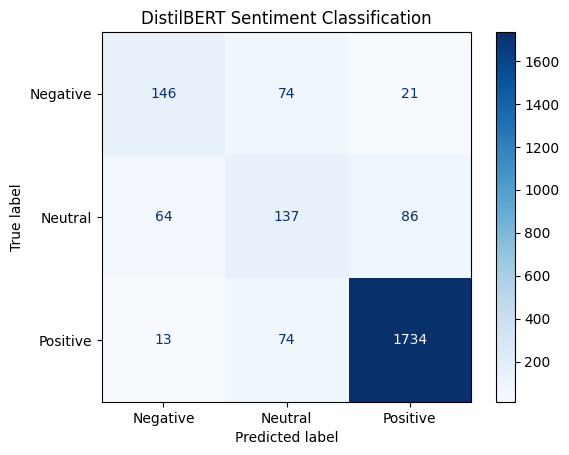

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt

# Predict on test data
test_results = trainer.predict(test_dataset)

y_pred = np.argmax(test_results.predictions, axis=1)
y_true = test_results.label_ids

# Accuracy
print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))

# Detailed classification report
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Neutral", "Positive"],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT Sentiment Classification")
plt.show()

In [ ]:
import time
import torch
import numpy as np

model.eval()

device = next(model.parameters()).device
sample_reviews = X_test.iloc[:500].tolist()
batch_size = 32

def predict_batch(texts):
    inputs = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(**inputs)

    return torch.argmax(outputs.logits, dim=1)

# Warm-up (not included in timing)
_ = predict_batch(sample_reviews[:batch_size])
if device.type == "cuda":
    torch.cuda.synchronize()

# Benchmark
start_time = time.perf_counter()

all_predictions = []

for i in range(0, len(sample_reviews), batch_size):
    batch = sample_reviews[i:i + batch_size]
    predictions = predict_batch(batch)
    all_predictions.extend(predictions.cpu().tolist())

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - start_time

print("Inference Benchmark")
print("-------------------")
print("Device:", device)
print("Reviews processed:", len(all_predictions))
print("Batch size:", batch_size)
print("Total inference time:", round(total_time, 3), "seconds")
print("Average time per review:", round((total_time / len(all_predictions)) * 1000, 2), "ms")
print("Throughput:", round(len(all_predictions) / total_time, 2), "reviews/second")

Inference Benchmark
-------------------
Device: cuda:0
Reviews processed: 500
Batch size: 32
Total inference time: 1.532 seconds
Average time per review: 3.06 ms
Throughput: 326.44 reviews/second


Save your trained model

In [ ]:
import shutil
from google.colab import files

# Save trained model and tokenizer
save_path = "./DistilBERT_Womens_Sentiment"

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

# Compress model folder
shutil.make_archive(
    "DistilBERT_Womens_Sentiment",
    "zip",
    save_path
)

print("Model and tokenizer saved successfully!")

# Download ZIP file
files.download("DistilBERT_Womens_Sentiment.zip")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Conclusion — Transformer-Based Sentiment Analysis Using DistilBERT


A three-class sentiment analysis model was successfully developed by fine-tuning the pre-trained DistilBERT (distilbert-base-uncased) transformer on the Women's Clothing Reviews dataset containing 23,483 reviews. Transfer learning was applied by using pretrained language representations and adapting the model to classify reviews into Negative, Neutral, and Positive sentiments based on customer ratings.

The dataset was divided into 80% training, 10% validation, and 10% testing data using stratified sampling. The model was fine-tuned for 2 epochs using a Tesla T4 GPU with mixed-precision training.

The model achieved 85.87% test accuracy and 68.51% Macro F1-score. It performed particularly well for positive sentiment (94.70% F1-score), while neutral sentiment remained challenging (47.90% F1-score), partly due to class imbalance.

Inference efficiency was evaluated using batch processing and FP16 precision. The model processed 500 reviews in 1.532 seconds, achieving a throughput of 326.44 reviews per second on the Tesla T4 GPU.

Overall, this task demonstrated the practical application of transfer learning, transformer fine-tuning, multi-class sentiment classification, and inference optimization. The trained model and tokenizer can be saved and reused for future predictions without repeating the training process.

Limitation: Sentiment labels were generated from star ratings rather than manually annotated review sentiment. Therefore, the model learns rating-based sentiment patterns, which may not always represent the actual emotion expressed in review text. Further improvements could include class-weighted training, hyperparameter tuning, and evaluation using human-annotated sentiment data.
